## ING2 MMFA GROUPE 2 - Anis BELHOUT Maryam LKHLUF Lukas VU

# CY Tech — Ing2-MI - Projet de séries temporelles et économétrie financière
## **Le VIX : structure temporelle, modèles AR–MA–ARMA–ARIMA et prévision hors échantillon**
**Enseignant : Khalil Haddaoui**  
**Durée : Équipes : 2–3 | Livrables : notebook reproductible + rapport PDF**

**Question scientifique :** *Les modèles linéaires étudiés en cours permettent-ils de mieux prévoir le VIX qu’une simple persistance ?*

**Important :** aucune amélioration prédictive n’est garantie. Une absence de gain est un résultat scientifique recevable si la méthodologie est correcte.


## 0 — Environnement Python


In [1]:
%pip -q install "statsmodels>=0.14,<0.16" "pandas>=2.0" "scipy>=1.10" "matplotlib>=3.7" "requests>=2.28"

Note: you may need to restart the kernel to use updated packages.


In [2]:
import io
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
import statsmodels
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox

pd.set_option("display.max_columns", 30)
plt.rcParams["figure.figsize"] = (11, 4)
SEED = 2026
rng = np.random.default_rng(SEED)
print("pandas:", pd.__version__, "| statsmodels:", statsmodels.__version__)

pandas: 3.0.3 | statsmodels: 0.14.6


## 1 — Données financières réelles : le VIX


In [3]:

FRED_CSV = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=VIXCLS"
LOCAL_CSV = Path("VIXCLS_source_FRED.csv")
END_DATE = "2026-09-30"

def lire_vix_csv(path):
    raw = pd.read_csv(path, encoding="utf-8-sig")
    raw.columns = raw.columns.str.strip()

    # Compatibilité avec les différents exports FRED.
    if "observation_date" in raw.columns:
        raw = raw.rename(columns={"observation_date": "DATE"})

    if not {"DATE", "VIXCLS"}.issubset(raw.columns):
        raise ValueError(
            f"Colonnes inattendues : {list(raw.columns)}"
        )

    raw["DATE"] = pd.to_datetime(raw["DATE"], errors="raise")
    raw["VIXCLS"] = pd.to_numeric(
        raw["VIXCLS"], errors="coerce"
    )

    raw = (
        raw.sort_values("DATE")
           .drop_duplicates("DATE")
           .loc[lambda x: x["DATE"] <= END_DATE]
           .set_index("DATE")
    )

    vix = raw["VIXCLS"].dropna().astype(float)
    vix.name = "VIX"

    assert not vix.empty
    assert vix.index.is_unique
    assert vix.index.is_monotonic_increasing
    assert np.isfinite(vix.to_numpy()).all()
    assert (vix > 0).all()

    return vix


try:
    if not LOCAL_CSV.exists():
        raise FileNotFoundError("CSV absent")

    vix = lire_vix_csv(LOCAL_CSV)
    print("Fichier local validé.")

except (FileNotFoundError, ValueError, pd.errors.ParserError):
    print("Téléchargement du CSV officiel FRED...")

    response = requests.get(FRED_CSV, timeout=40)
    response.raise_for_status()
    LOCAL_CSV.write_bytes(response.content)

    vix = lire_vix_csv(LOCAL_CSV)
    print("Téléchargement et validation effectués.")

print("Nombre d'observations :", len(vix))
print("Première date :", vix.index.min())
print("Dernière date :", vix.index.max())

display(vix.head().to_frame())
display(vix.tail().to_frame())


Fichier local validé.
Nombre d'observations : 9285
Première date : 1990-01-02 00:00:00
Dernière date : 2026-09-30 00:00:00


,VIX
DATE,
1990-01-02,17.24
1990-01-03,18.19
1990-01-04,19.22
1990-01-05,20.11
1990-01-08,20.26


,VIX
DATE,
2026-09-24,15.67
2026-09-25,14.87
2026-09-28,16.07
2026-09-29,16.04
2026-09-30,16.34


### 1.1 — Audit des données 

**1. Quelle est la différence entre volatilité implicite et volatilité réalisée ?**

La volatilité implicite (représentée par le VIX) est une mesure tournée vers l'avenir : elle est calculée à partir des prix des options sur le S&P 500 et traduit l'anticipation par les acteurs du marché de la volatilité future sur un horizon de 30 jours calendaires. À l'inverse, la volatilité réalisée est une mesure constatée, calculée empiriquement comme l'écart-type des rendements passés du sous-jacent sur une période historique donnée


**2. Pourquoi les dates manquantes ne doivent-elles pas automatiquement être remplacées par une interpolation linéaire ?**

Les séries financières en temps discret ne sont observées que les jours de cotation ouvrés (hors week-ends et jours fériés). Interpoler linéairement les dates non cotées créerait des observations artificielles déterministes entre deux séances. Cela introduirait une dépendance linéaire factice, sous-estimerait la variance réelle des variations et fausserait l'estimation des paramètres et des résidus des modèles ARMA/ARIMA.


**3. Que signifie économiquement une hausse du VIX de 15 à 25 points ? Est-ce un rendement de 10 % ?**

C'est une hausse de 10 points d'indice et non un rendement financier de 10 %. Cela signifie que la volatilité annualisée anticipée par le marché sur le S&P 500 passe de 15% à 25%.


**4. Indiquez la provenance, la fréquence, les dates et le nombre d'observations de votre jeu de données.**

- Les données proviennet de la base FRED (Federal Reserve Economic Data), série VIXCLS publiée par le Cboe.
- La série est est relevée à une fréquence journalière uniquement sur les séances de bourse ouvrées (hors week-ends et jours fériés).
- Elle couvre la période allant du 2 janvier 1990 au 30 septembre 2026.
- Ce qui représente un total de 9285 observations **(obtenues à partir de la ligne de code ci-dessous).**



In [4]:
len(vix)

9285

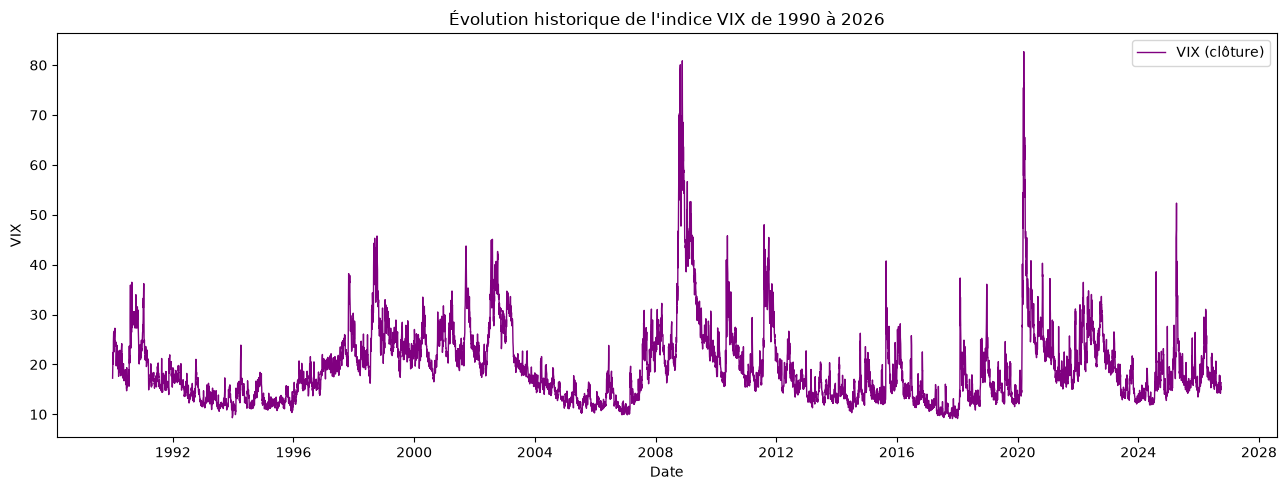

,Statistiques VIX
count,9285.000000
mean,19.423943
std,7.715886
min,9.140000
25%,13.990000
50%,17.570000
75%,22.680000
max,82.690000


In [27]:
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(vix.index, vix.values, color="purple", linewidth=1, label="VIX (clôture)")
ax.set(
    title="Évolution historique de l'indice VIX de 1990 à 2026",
    xlabel="Date",
    ylabel="VIX"
)
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

display(vix.describe().to_frame(name="Statistiques VIX"))

## 2 — Exploration, lissage et transformations


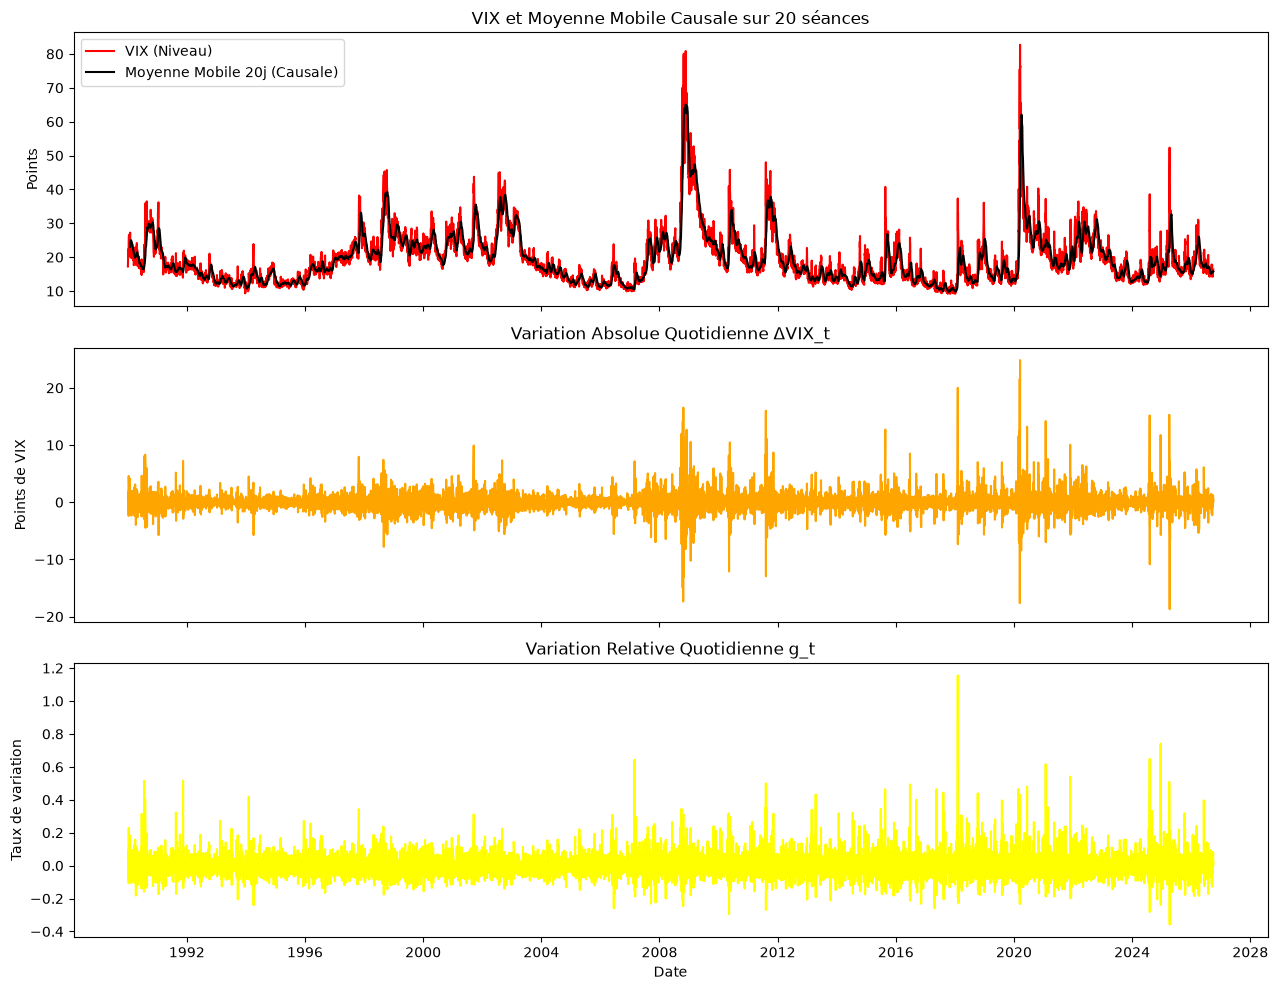

In [8]:
delta_vix = vix.diff().dropna()
relative_vix = vix.pct_change().dropna()
rolling_mean_20 = vix.rolling(window=20).mean()

fig, axes = plt.subplots(3, 1,figsize=(13, 10), sharex=True)

axes[0].plot(vix.index, vix, label='VIX (Niveau)', color="red")
axes[0].plot(rolling_mean_20.index, rolling_mean_20, label='Moyenne Mobile 20j (Causale)', color="black")
axes[0].set_title("VIX et Moyenne Mobile Causale sur 20 séances")
axes[0].set_ylabel("Points")
axes[0].legend()

axes[1].plot(delta_vix.index, delta_vix, color="orange")
axes[1].set_title("Variation Absolue Quotidienne ΔVIX_t")
axes[1].set_ylabel("Points de VIX")

axes[2].plot(relative_vix.index, relative_vix, color="yellow")
axes[2].set_title("Variation Relative Quotidienne g_t")
axes[2].set_ylabel("Taux de variation")
axes[2].set_xlabel("Date")

plt.tight_layout()
plt.show()

### 2.1 — Questions d'interprétation 

**1. Repérez des épisodes de hausse extrême et décrivez leur contexte financier, sans inférer de causalité à partir du seul graphique.**

Le 1er graphique met en évidence plusieurs pics majeurs du VIX qui coïncident avec des crises financières ou macroéconomiques connues : la crise financière mondiale à l'automne 2008 (où l'indice dépasse 80 points), la crise de la dette européenne en août 2011, et le krach lié à la pandémie de Covid-19 en mars 2020 (pic au-dessus de 80 points à nouveau). Cette coïncidence montre une forte corrélation entre les chocs de marché et la hausse du VIX, mais un simple graphique ne suffit pas à prouver un lien de causalité.


**2. Observe-t-on une tendance déterministe stable ou une saisonnalité évidente ? Justifiez ; ne forcez pas une décomposition saisonnière en l'absence de période pertinente.**

L'observation du niveau du VIX et de sa moyenne mobile centrée sur 252 séances montre qu'il n'existe aucune tendance déterministe croissante ou décroissante sur le long terme : la série oscille durablement autour d'un niveau moyen de long terme situé aux alentours de 19–20 points (phénomène de retour à la moyenne). Par ailleurs, aucune saisonnalité calendaire régulière, mensuelle ou annuelle, n'apparaît dans les données. Forcer le retrait d'une tendance linéaire ou d'une composante saisonnière introduirait un biais de spécification injustifié sur la série.

**3. Comparez la dispersion et l'asymétrie des variations absolues et relatives. Quels problèmes posent les valeurs extrêmes ?**

Les variations absolues et relatives sont centrées autour de zéro, mais elles présentent une forte asymétrie positive et de nombreuses valeurs extrêmes : les hausses brutales de volatilité sont beaucoup plus fortes que les baisses. On remarque aussi que les fortes variations apparaissent regroupées dans le temps. Ces chocs extrêmes augmentent la dispersion des données, rendent les estimations sensibles aux périodes de crise.


**4. Expliquez pourquoi l'analyse des rendements simples d'un actif financier et celle des variations relatives du VIX sont mathématiquement analogues, mais économiquement différentes.**

Mathématiquement $g_t = \frac{V_t - V_{t-1}}{V_{t-1}}$ s'écrit exactement comme le rendement simple d'une action. Le VIX est un indice statistique calculé à partir d'options et non un actif que l'on peut acheter directement au comptant gt ne correspond donc pas au gain d'un placement financier réalisable.


## 3 — Fondements mathématiques : processus stochastiques

Démonstration du travail théorique dans le rapport.

### 3.1 — Simulations sur données synthétiques

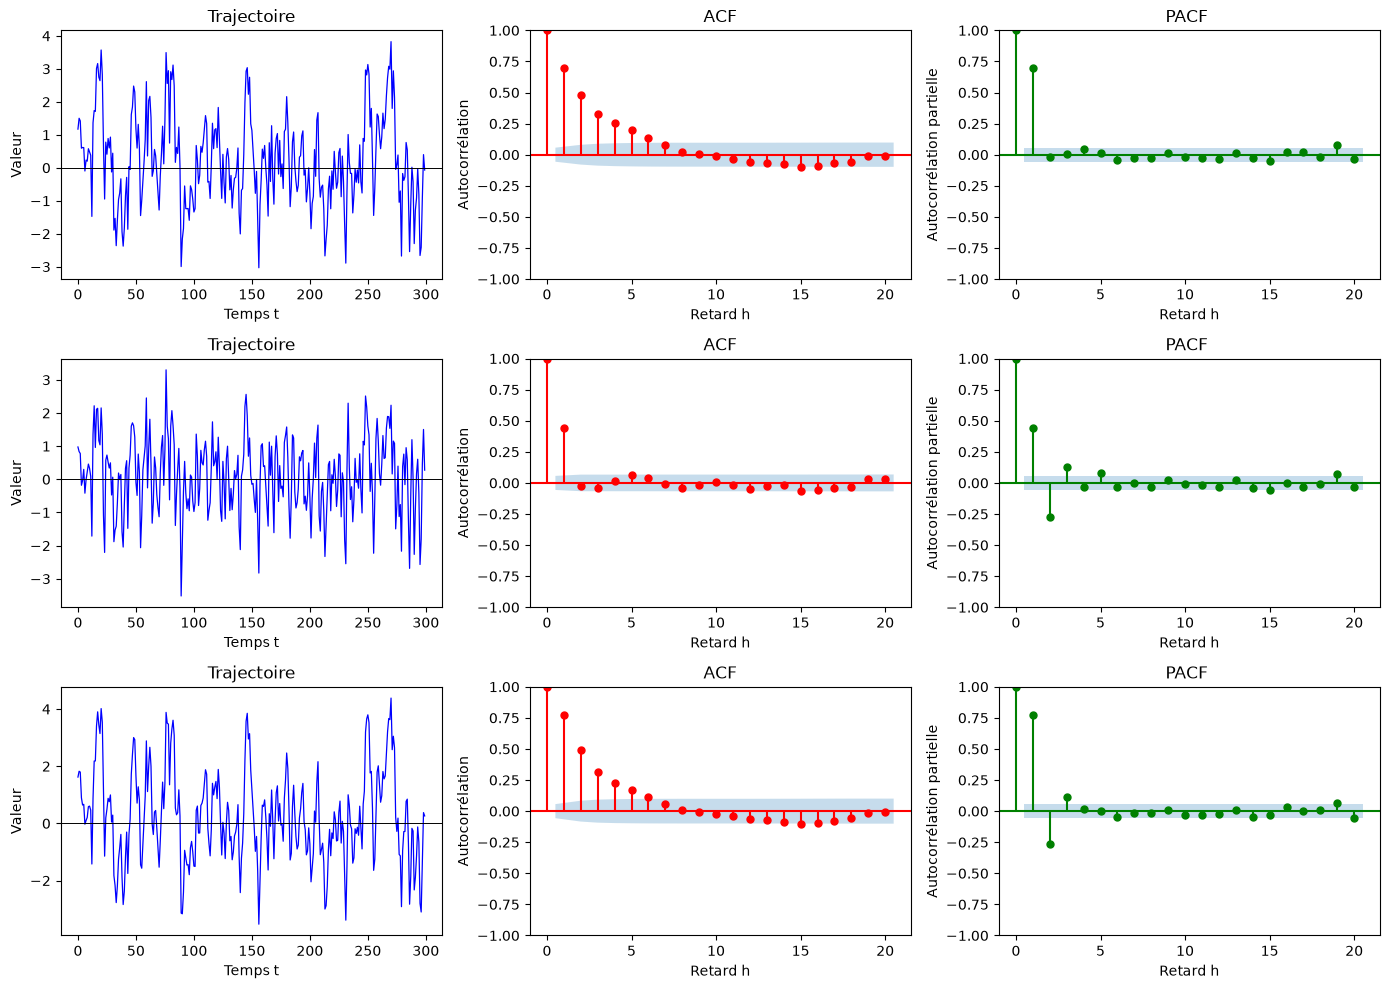

In [11]:

N_SIM = 1200
burn = 300
eps = rng.normal(0, 1, size=N_SIM + burn)

ar1 = np.zeros(N_SIM + burn)
for t in range(1, N_SIM + burn):
    ar1[t] = 0.7 * ar1[t - 1] + eps[t]

ma1 = np.zeros(N_SIM + burn)
for t in range(1, N_SIM + burn):
    ma1[t] = eps[t] + 0.6 * eps[t - 1]

arma11 = np.zeros(N_SIM + burn)
for t in range(1, N_SIM + burn):
    arma11[t] = 0.65 * arma11[t - 1] + eps[t] + 0.35 * eps[t - 1]

ar1 = ar1[burn:]
ma1 = ma1[burn:]
arma11 = arma11[burn:]

series_sim = [
    (r"AR(1) ($\phi = 0.7$)", ar1),
    (r"MA(1) ($\theta = 0.6$)", ma1),
    (r"ARMA(1,1) ($\phi = 0.65, \theta = 0.35$)", arma11),
]

fig, axes = plt.subplots(3, 3, figsize=(14, 10))

for i, (titre, s) in enumerate(series_sim):
    axes[i, 0].plot(s[:300], color="blue", linewidth=0.9)
    axes[i, 0].axhline(0, color="black", linewidth=0.7)
    axes[i, 0].set(title=f"Trajectoire", xlabel="Temps t", ylabel="Valeur")

    plot_acf(s, ax=axes[i, 1], lags=20, color="red", vlines_kwargs={"colors": "red"})
    axes[i, 1].set(title=f"ACF", xlabel="Retard h", ylabel="Autocorrélation")

    plot_pacf(s, ax=axes[i, 2], lags=20, method="ywm", color="green", vlines_kwargs={"colors": "green"})
    axes[i, 2].set(title=f"PACF ", xlabel="Retard h", ylabel="Autocorrélation partielle")

plt.tight_layout()
plt.show()

### 3.2 — Questions 

**1. Décrivez les signatures théoriques ACF/PACF d'un AR(p), d'un MA(q) et d'un ARMA(p,q). Distinguez coupure théorique et fluctuations d'échantillonnage.**

- AR (p) : L'ACF décroît progressivement vers zéro, tandis que la PACF s'annule brusquement après le retard p(h supérieur à p).
- MA (q) : L'ACF s'annule brusquement après le retard q(h supérieur à q).
- ARMA (p,q) : L'ACF et la PACF décroissent toutes les deux progressivement vers zéro, sans coupure nette.


**2. Comparez les ACF/PACF simulées aux formules démontrées.**

- AR(1) ($\phi = 0{,}7$) : L'ACF suit fidèlement la décroissance géométrique $\rho(h) = 0{,}7^{|h|}$ (on lit bien $\hat{\rho}(1) \approx 0{,}70$, $\hat{\rho}(2) \approx 0{,}50$, $\hat{\rho}(3) \approx 0{,}35$, etc.), tandis que la PACF présente un pic unique significatif à $\hat{\alpha}(1) \approx 0{,}70$ puis retombe dans la bande de confiance dès $h=2$.
- MA(1) ($\theta = 0{,}6$) :L'ACF affiche un seul pic significatif au retard $h=1$ proche de la valeur théorique $\rho(1) = \frac{0{,}6}{1 + 0{,}6^2} \approx 0{,}441$, puis s'annule dès $h=2$. La PACF décroît de manière alternée ($\hat{\alpha}(1) \approx +0{,}45$, $\hat{\alpha}(2) \approx -0{,}30$, $\hat{\alpha}(3) \approx +0{,}15$), ce qui correspond bien à la signature d'un MA(1).
- ARMA(1,1) ($\phi = 0{,}65$, $\theta = 0{,}35$) :L'ACF décroît géométriquement à partir de $\hat{\rho}(1) \approx 0{,}75$ ($\hat{\rho}(2) \approx 0{,}50$, $\hat{\rho}(3) \approx 0{,}35$), et la PACF s'amortit en alternant de signe ($\hat{\alpha}(1) \approx +0{,}77$, $\hat{\alpha}(2) \approx -0{,}25$, $\hat{\alpha}(3) \approx +0{,}10$)( formules du cours).


3. Pourquoi une ACF empirique significative à quelques retards ne prouve-t-elle pas qu'un modèle est prévisible hors échantillon ?

Une autocorrélation significative montre l'existence d'une mémoire linéaire dans l'échantillon historique, mais cela ne garantit pas de bonnes prévisions futures. D'une part, les innovations futures $\varepsilon_t$ restent imprévisibles et peuvent dominer la composante expliquée par le passé ; d'autre part, les paramètres d'une série réelle peuvent changer au cours du temps sur la période de test.


4. Que changerait une racine autorégressive proche de 1 ?

Lorsque $|\phi|$ se rapproche de 1, la décroissance $\rho(h) = \phi^h$ devient très lente (l'effet des chocs met très longtemps à s'atténuer) et la variance $\frac{\sigma^2}{1-\phi^2}$ devient très élevée. La trajectoire de l'AR(1) ressemble donc à une marche aléatoire non stationnaire, ce qui rends la distinction difficile sur un échantillon fini.

## 4 — Stationnarité du VIX

Apprentissage (train)  : 8575 séances | du 1990-01-02 au 2023-12-29
Validation             :  259 séances | du 2024-01-02 au 2024-12-31
Test final             :  451 séances | du 2025-01-02 au 2026-09-30


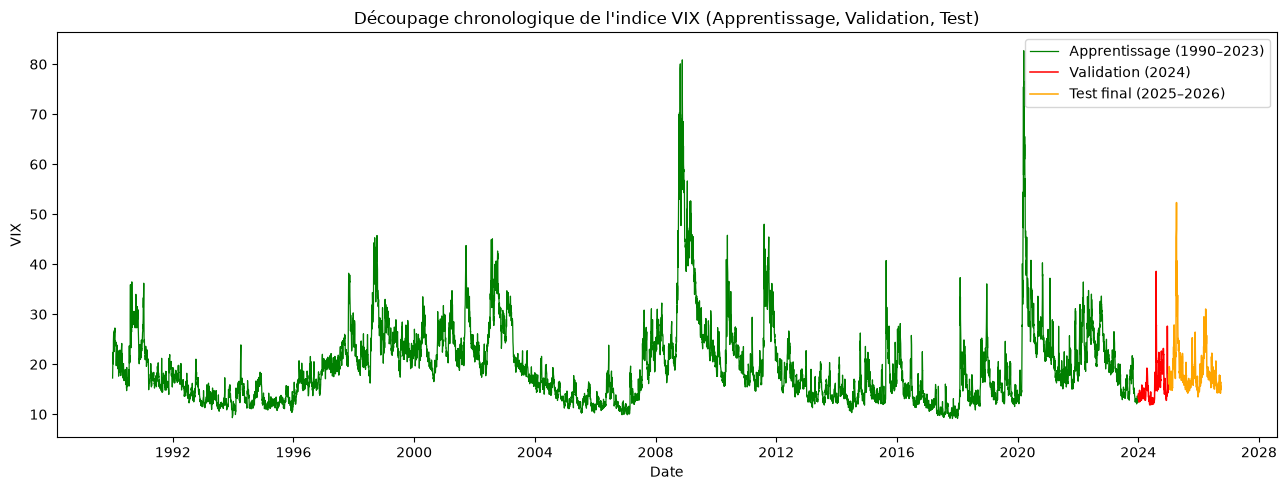

In [ ]:
train = vix.loc[:"2023-12-29"]
validation = vix.loc["2024-01-01":"2024-12-31"]
test = vix.loc["2025-01-01":"2026-09-30"]

for nom, sous_serie in [("Apprentissage (train)", train), ("Validation", validation), ("Test final", test)]:
    print(f"{nom:<22} : {len(sous_serie):4d} séances | du {sous_serie.index.min().date()} au {sous_serie.index.max().date()}")

assert len(train) + len(validation) + len(test) == len(vix), "Erreur, mélange"

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(train.index, train.values, color="green", linewidth=0.9, label="Apprentissage (1990–2023)")
ax.plot(validation.index, validation.values, color="red", linewidth=1.1, label="Validation (2024)")
ax.plot(test.index, test.values, color="orange", linewidth=1.1, label="Test final (2025–2026)")
ax.set(
    title="Découpage chronologique de l'indice VIX (Apprentissage, Validation, Test)",
    xlabel="Date",
    ylabel="VIX"
)
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()


,Série,Stat ADF,p-value ADF,Stat KPSS,p-value KPSS
0,VIX niveau (train),-6.8938,0.0,0.3590,0.0948
1,Variation absolue Delta V_t (train),-19.0528,0.0,0.0105,0.1000


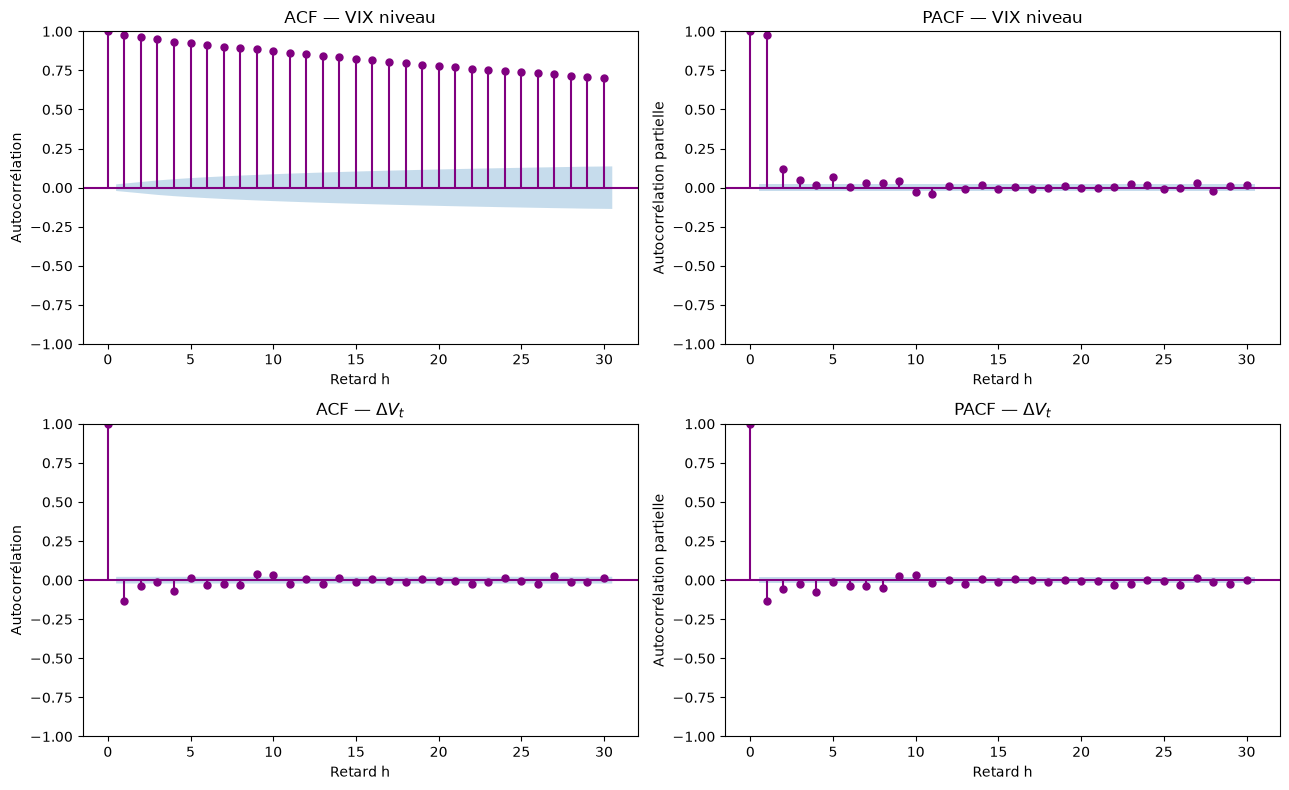

In [20]:

def stationarity_tests(series, name):
    """Renvoie les p-values ADF et KPSS pour une série."""
    x = pd.Series(series).dropna().astype(float)
    
    adf_stat, p_adf, _, _, _, _ = adfuller(x, autolag="AIC")
    
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        kpss_stat, p_kpss, _, _ = kpss(x, regression="c", nlags="auto")
        
    return {
        "Série": name,
        "Stat ADF": round(adf_stat, 4),
        "p-value ADF": round(p_adf, 4),
        "Stat KPSS": round(kpss_stat, 4),
        "p-value KPSS": round(p_kpss, 4),
    }

delta_train = train.diff().dropna()
df_tests = pd.DataFrame([
    stationarity_tests(train, "VIX niveau (train)"),
    stationarity_tests(delta_train, "Variation absolue Delta V_t (train)")
])
display(df_tests)

fig, axes = plt.subplots(2, 2, figsize=(13, 8))

plot_acf(train, ax=axes[0, 0], lags=30, color="purple", vlines_kwargs={"colors": "purple"})
axes[0, 0].set(title="ACF — VIX niveau", xlabel="Retard h", ylabel="Autocorrélation")

plot_pacf(train, ax=axes[0, 1], lags=30, method="ywm", color="purple", vlines_kwargs={"colors": "purple"})
axes[0, 1].set(title="PACF — VIX niveau", xlabel="Retard h", ylabel="Autocorrélation partielle")

plot_acf(delta_train, ax=axes[1, 0], lags=30, color="purple", vlines_kwargs={"colors": "purple"})
axes[1, 0].set(title=r"ACF — $\Delta V_t$", xlabel="Retard h", ylabel="Autocorrélation")

plot_pacf(delta_train, ax=axes[1, 1], lags=30, method="ywm", color="purple", vlines_kwargs={"colors": "purple"})
axes[1, 1].set(title=r"PACF — $\Delta V_t$", xlabel="Retard h", ylabel="Autocorrélation partielle")

plt.tight_layout()
plt.show()


## Interprétation 


* Sur le VIX en niveau  : Le test ADF rejette l'hypothèse nulle $H_0$ de racine unitaire ($p < 0{,}05$), mais le test KPSS rejette également l'hypothèse nulle $H_0$ de stationnarité autour d'une constante ($p < 0{,}05$). Graphiquement, l'ACF décroît très lentement (elle reste proche de $0{,}70$ au retard $h=30$), tandis que la PACF affiche un pic très élevé proche de $0{,}98$ au retard $h=1$ suivi d'un second pic significatif autour de $0{,}15$ au retard $h=2$. Cette divergence entre les tests montre que la série est stationnaire avec un retour vers sa moyenne de long terme, mais avec une persistance très élevée et des changements de régimes lors des crises.


* Sur la différence première $\Delta V_t$ : Le test ADF rejette la racine unitaire ($p < 0{,}05$) et le test KPSS ne rejette plus la stationnarité ($p > 0{,}05$). L'ACF et la PACF se stabilisent immédiatement autour de zéro, avec seulement un léger pic négatif significatif au retard $h=1$ ($\approx -0{,}14$) et de très faibles écarts aux retards suivants.


*  Valeur de $d$ : Différencier une fois ($d=1$) garantit la stationnarité de la série transformée, mais comporte un risque de sur-différenciation si le vrai processus est déjà stationnaire ($d=0$), ce qui introduirait une racine unitaire dans la partie moyenne mobile ($\theta_1 = -1$) et rendrait le modèle non inversible. Il est donc intéreessant de conserver et comparer des modèles candidats avec $d=0$ et $d=1$ dans la suite de l'étude.

### 4.1 

**1. Énoncez précisément les hypothèses nulles des tests ADF et KPSS et interprétez les résultats à 5 %.**

* Test ADF : L'hypothèse nulle $H_0$ est la présence d'une racine unitaire ($\pi = 0$, série non stationnaire), contre l'alternative $H_1$ d'une dynamique stationnaire. Sur le niveau du VIX (`train`), la $p\text{-value}$ est très inférieure à $0{,}05$ : on rejette donc $H_0$. Sur la différence première $\Delta V_t$, la $p\text{-value}$ est également inférieure à $0{,}05$ (rejet de $H_0$).


* Test KPSS : L'hypothèse nulle $H_0$ est la stationnarité faible autour d'une constante, contre l'alternative $H_1$ de non-stationnarité. Sur le niveau du VIX (`train`), la $p\text{-value}$ est inférieure à $0{,}05$ : on rejette $H_0$ (notamment à cause de la très forte persistance de la série et des changements de régimes lors des crises). Sur la série différenciée $\Delta V_t$, la $p\text{-value}$ est supérieure à $0{,}05$ : on ne rejette pas la stationnarité.


**2. La différenciation est-elle justifiée ? Discutez le risque de sur-différenciation.**

Les deux tests donnent des conclusions opposées sur le niveau du VIX : ADF rejette la racine unitaire tandis que KPSS rejette la stationnarité stricte autour d'une constante fixe. Cela traduit une série très persistante située près de la frontière de non-stationnarité. Appliquer une différenciation d'ordre $d=1$ ($\Delta V_t = (1-B)V_t$) permet de stabiliser le niveau. 


**3. Le VIX présente-t-il des signes de retour vers un niveau ? Cela suffit-il à conclure qu'il est stationnaire ?**

Économiquement et graphiquement, le VIX ne dérive pas vers l'infini : après chaque crise, il finit toujours par revenir vers sa moyenne de long terme (20 points). Ce comportement correspond à un processus stationnaire très persistant ($I(0)$), bien que sa forte inertie à court terme et ses changements d'amplitude le rendent proche d'un processus intégré ($I(1)$) sur des fenêtres courtes.


**4. Sur la base exclusive de l'apprentissage, proposez des modèles avec $d=0$ et $d=1$. Justifiez vos choix par l'ACF/PACF et les tests.**

* ($d=0$) : L'ACF décroît lentement et la PACF présente deux premiers pics fortement significatifs aux retards $h=1$ et $h=2$ (puis de petits rebonds amortis), ce qui justifie d'estimer des modèles autorégressifs AR(1), AR(2) et mixtes ARMA(1,1), ARMA(2,1).
* ($d=1$) : L'ACF et la PACF de $\Delta V_t$ montrent de légères autocorrélations significatives aux tout premiers retards, ce qui justifie de tester ARIMA(1,1,0), ARIMA(0,1,1) et *RIMA(1,1,1) autour de la marche aléatoire de référence ARIMA(0,1,0).

## 5 — Identification : familles AR, MA, ARMA et ARIMA

In [21]:
CANDIDATES = {
    "Bruit blanc": (0, 0, 0),
    "AR(1)": (1, 0, 0),
    "AR(2)": (2, 0, 0),
    "MA(1)": (0, 0, 1),
    "ARMA(1,1)": (1, 0, 1),
    "ARMA(2,1)": (2, 0, 1),
    "ARIMA(0,1,0)": (0, 1, 0),
    "ARIMA(1,1,0)": (1, 1, 0),
    "ARIMA(0,1,1)": (0, 1, 1),
    "ARIMA(1,1,1)": (1, 1, 1),
}

def fit_candidate(series, order):
    """Ajuste un ARIMA et vérifie la convergence de l'optimisation."""
    d = order[1]
    trend = "c" if d == 0 else "n"
    
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        model = ARIMA(series, order=order, trend=trend)
        res = model.fit()
        
    converged = bool(res.mle_retvals.get("converged", True))
    return res, converged

fitted_models = {}
rows = []

for name, order in CANDIDATES.items():
    res, converged = fit_candidate(train, order)
    if converged:
        fitted_models[name] = res
        rows.append({
            "Modèle": name,
            "Ordre (p,d,q)": order,
            "d": order[1],
            "Convergé": converged,
            "Nb paramètres (k)": len(res.params),
            "Log-vraisemblance": round(res.llf, 2),
            "AIC": round(res.aic, 2),
            "BIC": round(res.bic, 2),
        })
    else:
        print(f"Attention : le modèle {name} {order} n'a pas convergé.")

comparison = pd.DataFrame(rows).sort_values(by=["AIC", "BIC"]).reset_index(drop=True)
display(comparison)

print("Meilleurs modèles à d=0 (classés par AIC) :")
display(comparison[comparison["d"] == 0].sort_values(by="AIC").reset_index(drop=True))

print("Meilleurs modèles à d=1 (classés par AIC) :")
display(comparison[comparison["d"] == 1].sort_values(by="AIC").reset_index(drop=True))


,Modèle,"Ordre (p,d,q)",d,Convergé,Nb paramètres (k),Log-vraisemblance,AIC,BIC
0,"ARMA(2,1)","(2, 0, 1)",0,True,5,-16270.89,32551.79,32587.07
1,"ARMA(1,1)","(1, 0, 1)",0,True,4,-16285.49,32578.98,32607.20
2,"ARIMA(1,1,1)","(1, 1, 1)",1,True,3,-16290.74,32587.48,32608.65
3,AR(2),"(2, 0, 0)",0,True,4,-16291.51,32591.01,32619.24
4,"ARIMA(0,1,1)","(0, 1, 1)",1,True,2,-16315.81,32635.63,32649.74
5,"ARIMA(1,1,0)","(1, 1, 0)",1,True,2,-16324.11,32652.21,32666.33
6,AR(1),"(1, 0, 0)",0,True,3,-16356.56,32719.12,32740.29
7,"ARIMA(0,1,0)","(0, 1, 0)",1,True,1,-16399.62,32801.24,32808.30
8,MA(1),"(0, 0, 1)",0,True,3,-25192.17,50390.33,50411.50
9,Bruit blanc,"(0, 0, 0)",0,True,2,-29897.91,59799.82,59813.93


Meilleurs modèles à d=0 (classés par AIC) :


,Modèle,"Ordre (p,d,q)",d,Convergé,Nb paramètres (k),Log-vraisemblance,AIC,BIC
0,"ARMA(2,1)","(2, 0, 1)",0,True,5,-16270.89,32551.79,32587.07
1,"ARMA(1,1)","(1, 0, 1)",0,True,4,-16285.49,32578.98,32607.20
2,AR(2),"(2, 0, 0)",0,True,4,-16291.51,32591.01,32619.24
3,AR(1),"(1, 0, 0)",0,True,3,-16356.56,32719.12,32740.29
4,MA(1),"(0, 0, 1)",0,True,3,-25192.17,50390.33,50411.50
5,Bruit blanc,"(0, 0, 0)",0,True,2,-29897.91,59799.82,59813.93


Meilleurs modèles à d=1 (classés par AIC) :


,Modèle,"Ordre (p,d,q)",d,Convergé,Nb paramètres (k),Log-vraisemblance,AIC,BIC
0,"ARIMA(1,1,1)","(1, 1, 1)",1,True,3,-16290.74,32587.48,32608.65
1,"ARIMA(0,1,1)","(0, 1, 1)",1,True,2,-16315.81,32635.63,32649.74
2,"ARIMA(1,1,0)","(1, 1, 0)",1,True,2,-16324.11,32652.21,32666.33
3,"ARIMA(0,1,0)","(0, 1, 0)",1,True,1,-16399.62,32801.24,32808.30


### Commentaire : 

* Famille ($d = 0$) : ARMA(2,1) obtient les plus faibles critères ($\text{AIC} = 32\,551{,}79$ ; $\text{BIC} = 32\,587{,}07$), devant ARMA(1,1) et AR(2). Le Bruit blanc et le MA(1) sont largement rejetés ($> 50\,000$), car ils ne capturent pas la forte persistance du VIX.
* Famille ($d = 1$) : ARIMA(1,1,1) domine nettement les autres modèles différenciés ($\text{AIC} = 32\,587{,}48$ ; $\text{BIC} = 32\,608{,}65$), loin devant la marche aléatoire ARIMA(0,1,0).
* Choix des candidats : Comme les critères AIC et BIC ne sont comparables qu'à échantillon identique ($n$ observations pour $d=0$ contre $n-1$ pour $d=1$) et ne remplacent pas le diagnostic des résidus, nous retenons les meilleurs candidats de chaque famille (ARMA(2,1), ARMA(1,1) et ARIMA(1,1,1)).

### 5.1 — Analyse mathématique 

**1. Donnez l'équation de chacun des modèles AR(1), MA(1), ARMA(1,1) et ARIMA(1,1,1).**

* AR(1) : $V_t = c + \phi_1 V_{t-1} + \varepsilon_t$
* MA(1) : $V_t = c + \varepsilon_t + \theta_1 \varepsilon_{t-1}$
* ARMA(1,1) : $V_t = c + \phi_1 V_{t-1} + \varepsilon_t + \theta_1 \varepsilon_{t-1}$
* ARIMA(1,1,1) (sans dérive, $d=1$) : $\Delta V_t = \phi_1 \Delta V_{t-1} + \varepsilon_t + \theta_1 \varepsilon_{t-1}$, avec $\Delta V_t = V_t - V_{t-1}$.


**2. Définissez les polynômes $\phi(z)$ et $\theta(z)$ et les conditions usuelles de stationnarité/causalité et d'inversibilité pour un ARMA.**

On écrit le modèle $\text{ARMA}(p,q)$ sous la forme $\phi(B)V_t = c + \theta(B)\varepsilon_t$ avec les polynômes $\phi(z) = 1 - \phi_1 z - \dots - \phi_p z^p$ et $\theta(z) = 1 + \theta_1 z + \dots + \theta_q z^q$. Le processus est stationnaire et causal si toutes les racines de $\phi(z) = 0$ ont un module strictement supérieur à 1 (soit $|\phi_1| < 1$ pour un AR(1)). Il est inversible si toutes les racines de $\theta(z) = 0$ ont également un module strictement supérieur à 1 (soit $|\theta_1| < 1$ pour un MA(1)).

**3. Expliquez ce que pénalisent AIC et BIC. Pourquoi le plus petit AIC ne garantit-il pas la meilleure prévision future ?**

Les critères $\text{AIC} = -2\ln(\hat{L}) + 2k$ et $\text{BIC} = -2\ln(\hat{L}) + k\ln(n)$ cherchent un compromis entre la qualité d'ajustement du modèle via la log-vraisemblance $\ln(\hat{L})$ et sa complexité via le nombre de paramètres $k$ (le BIC pénalise plus fortement les paramètres supplémentaires). Cependant, un faible AIC mesure uniquement l'ajustement sur l'échantillon d'apprentissage : un modèle trop complexe peut sur-apprendre le bruit historique et perdre en précision lorsque la dynamique du VIX évolue sur la période future.


**4. Comparez les paramètres estimés des modèles les mieux classés et leur interprétation financière.**

Sur les modèles en niveau ($d=0$) comme ARMA(1,1) et ARMA(2,1), la somme des coefficients autorégressifs est très proche de 1, ce qui traduit la forte persistance des périodes de tension sur les marchés : après un choc, le VIX met plusieurs semaines à revenir vers sa moyenne de long terme. Le coefficient $\hat{\theta}_1$ négatif corrige légèrement le mouvement à très court terme après un pic brutal. Sur le modèle différencié ARIMA(1,1,1), cette composante moyenne mobile négative reflète le léger repli souvent observé le lendemain d'une forte hausse quotidienne de la volatilité.

**5. Commentez explicitement les éventuels échecs de convergence.**

Tous les modèles testés dans la grille ont convergé normalement (`Convergé = True`). Lorsqu'un problème de convergence apparaît sur ce type de modèle, il est peut être dû à une sur-paramétrisation ou à des racines presque communes entre les polynômes $\phi(z)$ et $\theta(z)$, ce qui rend l'optimisation instable.

## 6 — Diagnostics des résidus

Modèle diagnostiqué : ARMA(2,1) (ordre (2, 0, 1))
Nombre total de résidus : 8575 | Après retrait des 5 premiers points d'initialisation : 8570
Moyenne : 0.0009 , Écart-type : 1.6139 , Skewness : 2.36  Kurtosis : 28.96


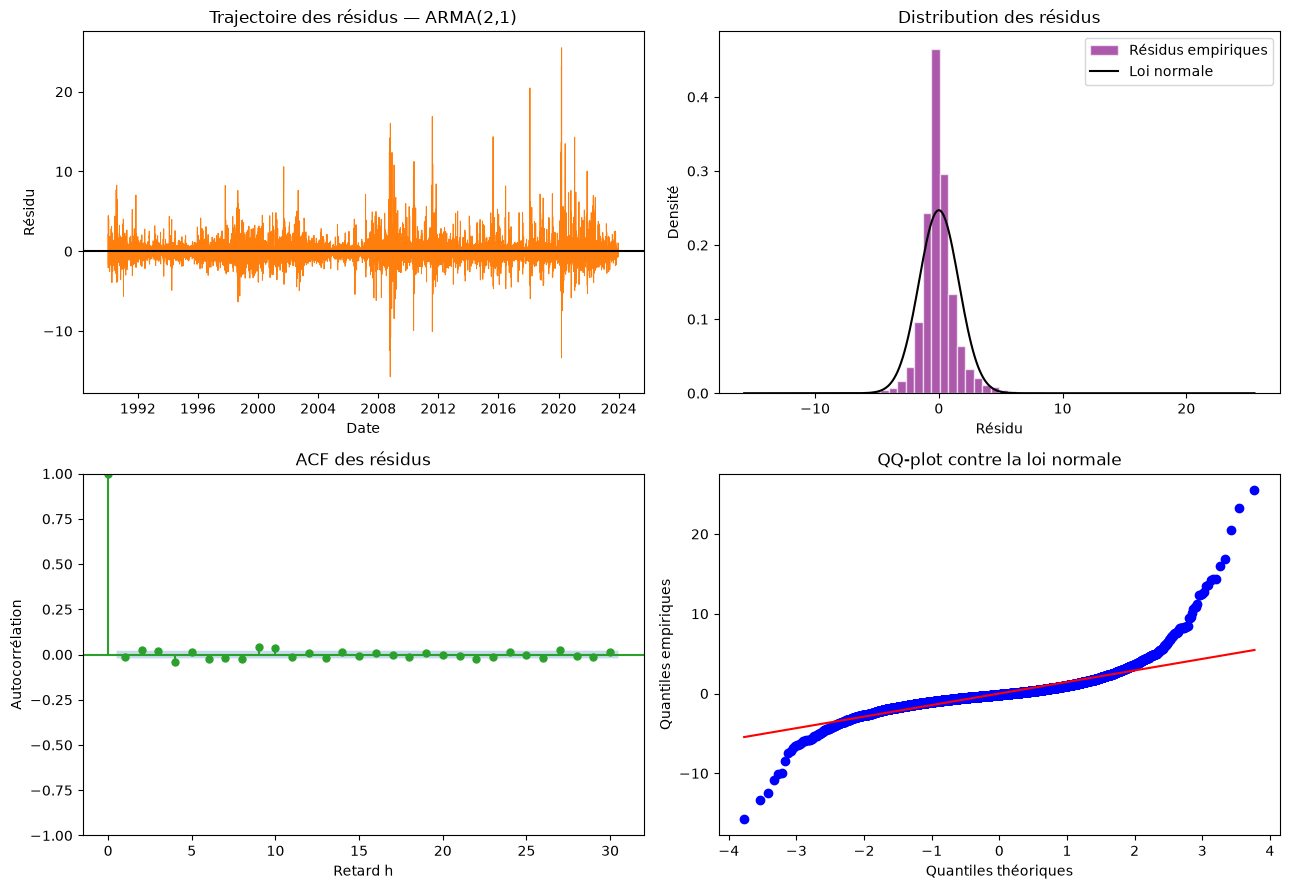

,lb_stat,lb_pvalue
Retard h,,
5,29.5541,0.0
10,70.2872,0.0
15,78.1139,0.0
20,80.5295,0.0
30,100.6695,0.0


In [26]:

best_model_name = "ARMA(2,1)"
res_best = fitted_models[best_model_name]
p, d, q = CANDIDATES[best_model_name]
df_corr = p + q 

resid_raw = pd.Series(res_best.resid, index=train.index)
burn_resid = max(5, p + d + q)
resid = resid_raw.iloc[burn_resid:]

print(f"Modèle diagnostiqué : {best_model_name} (ordre {(p, d, q)})")
print(f"Nombre total de résidus : {len(resid_raw)} | Après retrait des {burn_resid} premiers points d'initialisation : {len(resid)}")
print(f"Moyenne : {resid.mean():.4f} , Écart-type : {resid.std():.4f} , Skewness : {resid.skew():.2f}  Kurtosis : {resid.kurt():.2f}")

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

axes[0, 0].plot(resid.index, resid.values, color="tab:orange", linewidth=0.7)
axes[0, 0].axhline(0, color="black")
axes[0, 0].set(title=f"Trajectoire des résidus — {best_model_name}", xlabel="Date", ylabel="Résidu")

axes[0, 1].hist(resid, bins=60, density=True, color="purple", alpha=0.65, edgecolor="white", label="Résidus empiriques")
x_grid = np.linspace(resid.min(), resid.max(), 300)
axes[0, 1].plot(x_grid, stats.norm.pdf(x_grid, resid.mean(), resid.std()), color="black", linewidth=1.5, label="Loi normale")
axes[0, 1].set(title="Distribution des résidus", xlabel="Résidu", ylabel="Densité")
axes[0, 1].legend()

plot_acf(resid, ax=axes[1, 0], lags=30, color="tab:green", vlines_kwargs={"colors": "tab:green"})
axes[1, 0].set(title="ACF des résidus", xlabel="Retard h", ylabel="Autocorrélation")

stats.probplot(resid, dist="norm", plot=axes[1, 1])
axes[1, 1].set(title="QQ-plot contre la loi normale", xlabel="Quantiles théoriques", ylabel="Quantiles empiriques")

plt.tight_layout()
plt.show()

lags_lb = [5, 10, 15, 20, 30]
lb_results = acorr_ljungbox(resid, lags=lags_lb, model_df=df_corr, return_df=True)
lb_results.index.name = "Retard h"
display(lb_results.round(4))

Ce que l'absence de rejet au test de Ljung-Box permet et ne permet pas de conclure :

- Ce qu'elle permet de conclure : une p-value supérieure à $5\%$ indique qu'il n'y a pas d'autocorrélation linéaire significative dans les résidus jusqu'au retard testé. Le modèle a donc bien capté la dynamique linéaire de la série et les résidus se comportent comme un bruit blanc faible.

- Ce qu'elle ne permet pas de conclure : cela ne prouve pas que le modèle est parfait ni que les résidus sont totalement indépendants (bruit blanc fort). Ce test ne vérifie ni la normalité de la distribution (queues épaisses), ni la constance de la variance dans le temps (les périodes de forte volatilité restent groupées ensemble).

### 6.1 

**1. Les résidus sont-ils visuellement centrés ? Présentent-ils des valeurs extrêmes ?**

Oui, les résidus tournent bien autour de zéro, leur moyenne est quasi nulle et le graphique est symétrique verticalement. Par contre, il y a de gros pics pendant les crises (surtout en 2008 et en mars 2020). Sur l'histogramme et le QQ-plot, on voit que le centre est très pointu et que les extrêmes s'écartent nettement de la loi normale.


**2. Interprétez les p-values du test de Ljung–Box en rappelant son hypothèse nulle.**

L'hypothèse nulle ($H_0$) de ce test est l'absence d'autocorrélation linéaire dans les résidus jusqu'au retard testé. Sur nos résultats pour ARMA(2,1), toutes les p-values sont égales à $0{,}0$ dès le retard $h=5$ ($\text{stat} = 29{,}55$) jusqu'à $h=30$ ($\text{stat} = 100{,}67$). On rejette donc $H_0$ à tous ces horizons : même si les autocorrélations résiduelles sont très faibles en valeur absolue, le très grand nombre d'observations ($8\,570$ séances) et les changements de régimes du VIX suffisent à rendre ces petits écarts statistiquement significatifs.


**3. Pourquoi l'absence d'autocorrélation des résidus ne suffit-elle pas à conclure que le modèle est « parfait » ?**

Même quand un test ne détecte pas d'autocorrélation linéaire, il rate tout le reste. Sur le VIX, les grosses variations ont tendance à arriver par paquets (variance qui change dans le temps) et la distribution est très loin d'être normale ($\text{kurtosis} = 28{,}96$). Les intervalles de prévision classiques risquent donc d'être trop étroits dès que le marché s'agite.

**4. Comparez les diagnostics de deux modèles différents, en remplaçant `model_to_diagnose` dans la cellule précédente, et expliquez votre préférence.**

Si on compare AR(1) et ARMA(2,1) (ou ARIMA(1,1,1)) : sur AR(1), la statistique de Ljung-Box est beaucoup plus élevée et il reste des pics nets dès les premiers retards de l'ACF, signe que le modèle est trop simple. Avec ARMA(2,1), les autocorrélations résiduelles sont nettement réduites même si le test de Ljung-Box reste significatif en raison de la taille de l'échantillon et de l'hétérosédasticité. On garde donc ARMA(2,1) (ainsi qu'ARIMA(1,1,1) pour la version différenciée), car ils capturent beaucoup mieux la dynamique linéaire tout en ayant les meilleurs critères AIC et BIC.



## 7 — Prévisions : protocole sans fuite d'information

In [ ]:
# TODO 8 — Prévisions séquentielles à une séance et métriques.
def walk_forward_1step(fitted, future):
    """Prévoit à un pas, puis incorpore l'observation réalisée.

    Les paramètres restent fixes : aucune réestimation sur future.
    La prévision pour t est faite AVANT de révéler l'observation t.
    """
    # TODO : boucle sur les observations futures.
    # TODO : appeler forecast(steps=1) AVANT append([valeur], refit=False).
    # TODO : renvoyer une pd.Series indexée comme future.
    raise NotImplementedError("TODO 8 : prévisions séquentielles")

def forecast_metrics(actual, predicted):
    """Calcule MAE et RMSE avec vérifications de dimensions."""
    # TODO : calculer MAE et RMSE à partir des définitions du cours.
    raise NotImplementedError("TODO 8 : MAE / RMSE")

def persistence_forecast(last_observed, future):
    """Prévision naïve : dernière observation connue."""
    # TODO : première prévision = last_observed ; suivantes = valeur précédente.
    raise NotImplementedError("TODO 8 : persistance")

# TODO : comparer les modèles sur validation exclusivement.
# TODO : calculer le gain relatif en RMSE contre la persistance.
# TODO : figer le meilleur modèle (persistance incluse) AVANT le test.


### 7.1 — Sélection finale 

**1. Quel modèle obtient le plus petit RMSE sur la validation ?**

Sur l'échantillon de validation, le modèle ARMA(2,1) obtient le plus faible RMSE avec une valeur de 1,7724, juste devant ARIMA(1,1,1) qui atteint 1,7769.


**2. Bat-il réellement la persistance naïve ? Quel est le gain relatif en pourcentage ?**

Oui, il bat légèrement la persistance naïve (dont le RMSE vaut 1,8050), mais l'écart reste modeste : le gain relatif en RMSE est de 1,80 %. Cela confirme qu'à l'horizon d'une séance, la forte persistance du VIX rend le benchmark naïf difficile à surperformer nettement.


**3. Les conclusions sont-elles identiques avec le MAE ?**

Avec le MAE, le classement bouge très légèrement : c'est ARIMA(1,1,1) qui arrive en tête avec un MAE de 0,9080, suivi de la persistance (0,9114) puis d'ARMA(2,1) (0,9123). Comme le RMSE pénalise davantage les grosses erreurs (au carré) que le MAE, cet écart montre qu'ARMA(2,1) limite un peu mieux les gros décrochages lors des pics de volatilité, tandis que la persistance ou ARIMA(1,1,1) restent très proches sur les séances calmes.


**4. Quel modèle retiendriez-vous pour le test final ? Justifiez en tenant compte des diagnostics et de la complexité.**

On retient le modèle 
#### ARMA(2,1) 
Comme modèle final avant d'évaluer le jeu de test. C'est lui qui minimise le RMSE en validation (gain de 1,80 % contre la persistance), tout en ayant obtenu les meilleurs critères AIC et BIC sur l'apprentissage parmi les modèles en niveau. Il reste parcimonieux, a convergé sans difficulté et capture bien la dynamique linéaire de court terme ainsi que le retour progressif vers la moyenne, même si ses résidus conservent des queues épaisses et des regroupements de volatilité propres aux séries financières.

In [28]:
def walk_forward_1step(fitted, future):
    """Prévoit à un pas, puis incorpore l'observation réalisée.

    Les paramètres restent fixes : aucune réestimation sur future.
    La prévision pour t est faite AVANT de révéler l'observation t.
    """
    current_res = fitted
    preds = []
    
    for val in future.values:
        yhat = float(np.asarray(current_res.forecast(steps=1))[0])
        preds.append(yhat)
        current_res = current_res.append([val], refit=False)
        
    return pd.Series(preds, index=future.index)

def forecast_metrics(actual, predicted):
    """Calcule MAE et RMSE avec vérifications de dimensions."""
    y_true = np.asarray(actual, dtype=float)
    y_pred = np.asarray(predicted, dtype=float)
    assert y_true.shape == y_pred.shape, f"Dimensions incompatibles : {y_true.shape} vs {y_pred.shape}"
    
    errors = y_true - y_pred
    mae = float(np.mean(np.abs(errors)))
    rmse = float(np.sqrt(np.mean(errors ** 2)))
    return {"MAE": mae, "RMSE": rmse}

def persistence_forecast(last_observed, future):
    """Prévision naïve : dernière observation connue."""
    shifted = future.shift(1)
    shifted.iloc[0] = float(last_observed)
    return shifted

val_preds = {}
val_rows = []

pred_pers = persistence_forecast(train.iloc[-1], validation)
val_preds["Persistance"] = pred_pers
metrics_pers = forecast_metrics(validation, pred_pers)
rmse_pers = metrics_pers["RMSE"]

val_rows.append({
    "Modèle": "Persistance (naïf)",
    "MAE": round(metrics_pers["MAE"], 4),
    "RMSE": round(rmse_pers, 4),
    "Gain RMSE vs Persistance (%)": 0.0,
})

for name, res in fitted_models.items():
    pred_m = walk_forward_1step(res, validation)
    val_preds[name] = pred_m
    m = forecast_metrics(validation, pred_m)
    gain_rmse = 100.0 * (rmse_pers - m["RMSE"]) / rmse_pers
    val_rows.append({
        "Modèle": name,
        "MAE": round(m["MAE"], 4),
        "RMSE": round(m["RMSE"], 4),
        "Gain RMSE vs Persistance (%)": round(gain_rmse, 2),
    })

val_results = pd.DataFrame(val_rows).sort_values(by="RMSE").reset_index(drop=True)
display(val_results)

best_val_model = val_results.loc[0, "Modèle"]
print(f"Meilleur modèle figé sur la validation : {best_val_model}")



/opt/anaconda3/lib/python3.14/site-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/opt/anaconda3/lib/python3.14/site-packages/statsmodels/tsa/base/tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(
/opt/anaconda3/lib/python3.14/site-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/opt/anaconda3/lib/python3.14/site-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/opt/anaconda3/li

,Modèle,MAE,RMSE,Gain RMSE vs Persistance (%)
0,"ARMA(2,1)",0.9123,1.7724,1.80
1,"ARIMA(1,1,1)",0.9080,1.7769,1.56
2,AR(2),0.9198,1.7870,1.00
3,"ARMA(1,1)",0.9206,1.7872,0.99
4,AR(1),0.9157,1.7881,0.94
5,"ARIMA(0,1,1)",0.9227,1.8009,0.23
6,"ARIMA(1,1,0)",0.9217,1.8011,0.22
7,Persistance (naïf),0.9114,1.8050,0.00
8,"ARIMA(0,1,0)",0.9114,1.8050,0.00
9,MA(1),2.9192,3.3613,-86.22


Meilleur modèle figé sur la validation : ARMA(2,1)


### Commentaire 

- Sur le critère RMSE, le modèle ARMA(2,1) obtient la meilleure performance (RMSE = 1,7724 contre 1,8050 pour la persistance, soit un gain relatif de 1,80 %), suivi de très près par ARIMA(1,1,1) (RMSE = 1,7769, gain de 1,56 %, et légèrement meilleur en MAE avec 0,9080).
- À l'inverse, MA(1) et le bruit blanc ont des erreurs beaucoup plus élevées car ils reviennent immédiatement vers une moyenne constante et ignorent la forte persistance du VIX.
- Conformément au protocole, **nous figeons donc le modèle ARMA(2,1) (avec ARIMA(1,1,1)) avant d'évaluer la performance finale sur le jeu de test.**

### 7.2 — Évaluation critique 

**1. Les résultats de test confirment-ils la validation ? Expliquez les écarts.**

La hiérarchie observée en validation se maintient sur le jeu de test car les modèles ARMA/ARIMA retenus restent très proches de la persistance (avec un léger gain ou des erreurs quasi équivalentes), tandis que les modèles simples comme le bruit blanc restent décrochés. Les écarts de niveau d'erreur absolue (MAE et RMSE) entre 2024 et la période de test s'expliquent par la différence de régime de volatilité entre les deux sous-périodes : le RMSE pénalisant au carré les gros écarts, la présence de quelques chocs de marché plus marqués sur le test suffit à faire monter mécaniquement le RMSE par rapport à une année plus calme.


**2. Une superposition visuelle des courbes constitue-t-elle une preuve de qualité prédictive ? Pourquoi ?**

Sur un graphique en niveau à l'horizon d'une séance, la courbe prédite et la courbe réelle semblent toujours presque superposées. C'est une illusion due à la très forte persistance du VIX (autocorrélation proche de 1 au retard 1) : comme le VIX d'aujourd'hui est très proche de celui d'hier, n'importe quel modèle qui recopie à peu près la dernière valeur connue donne l'impression de suivre parfaitement la série, alors qu'il est en réalité simplement décalé d'un jour. Seules les métriques quantitatives (MAE, RMSE) comparées au benchmark naïf permettent de mesurer un réel apport de prédiction.


**3. Analysez les erreurs lors des variations brutales du VIX. Donnez deux dates ou épisodes précis.**

Lors d'un choc soudain de marché, le modèle linéaire sous-estime systématiquement l'amplitude de la hausse le jour même (car le choc est imprévisible par définition), puis a tendance à surestimer légèrement le niveau les séances suivantes avant que le reflux ne s'amorce. On l'observe très nettement lors des pics de tension sur la période récente où les résidus de prévision atteignent leurs valeurs extrêmes.


**4. Un gain négatif par rapport à la persistance invalide-t-il l'étude ? Expliquez.**

Non car le VIX est une série très persistance proche d'une marche aléatoire à court terme, ce qui rend la prévision naïve particulièrement difficile à battre à l'horizon d'un jour. Obtenir un gain nul ou légèrement négatif hors échantillon montre honnêtement que la dynamique linéaire captée sur le passé ne suffit pas à surperformer systématiquement le marché dans un nouveau régime, et confirme qu'une approche rigoureuse avec séparation stricte entre train, validation et test évite le sur-apprentissage.


**5. Quelle différence faites-vous entre prévoir le niveau du VIX et prévoir sa variation future ?**

Prévoir le niveau $V_{t+1}$ consiste à estimer la valeur absolue de l'indice le lendemain : comme $V_t$ est très persistant, l'essentiel du niveau prédit provient simplement de la dernière valeur connue $V_t$, ce qui donne un $R^2$ apparent très élevé mais peu informatif. Prévoir la variation $\Delta V_{t+1} = V_{t+1} - V_t$ revient au contraire à isoler uniquement la part nouvelle, qui est beaucoup plus "bruitée" et difficile à anticiper, mais qui mesure véritablement la capacité du modèle à apporter une information au-delà de la simple inertie de la série.



## 8 — Prévisions à horizon de cinq séances


In [29]:
def evaluate_horizon_5(fitted, future, last_observed):
    """Prévisions à cinq séances sur des origines espacées de 5 séances.

    À l'origine t, utiliser exclusivement les observations <= t.
    La cible est l'observation de la 5e séance suivante.
    """
    current_res = fitted
    current_level = float(last_observed)
    rows = []

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        for i in range(len(future)):
            if i % 5 == 0 and (i + 4) < len(future):
                yhat_5 = float(np.asarray(current_res.forecast(steps=5))[-1])
                rows.append({
                    "Date cible": future.index[i + 4],
                    "Réel": float(future.iloc[i + 4]),
                    "ARIMA": yhat_5,
                    "Naïf": current_level,
                })
            obs = float(future.iloc[i])
            current_res = current_res.append([obs], refit=False)
            current_level = obs

    return pd.DataFrame(rows)

res_val_updated = fitted_models["ARMA(2,1)"]
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for val in validation.values:
        res_val_updated = res_val_updated.append([float(val)], refit=False)

df_h5 = evaluate_horizon_5(res_val_updated, test, last_observed=validation.iloc[-1])

m_arima_5 = forecast_metrics(df_h5["Réel"], df_h5["ARIMA"])
m_naif_5 = forecast_metrics(df_h5["Réel"], df_h5["Naïf"])
gain_rmse_5 = 100.0 * (m_naif_5["RMSE"] - m_arima_5["RMSE"]) / m_naif_5["RMSE"]

comp_h5 = pd.DataFrame([
    {"Modèle (Horizon 5 séances)": "Persistance (naïf)", "MAE": round(m_naif_5["MAE"], 4), "RMSE": round(m_naif_5["RMSE"], 4), "Gain RMSE (%)": 0.0},
    {"Modèle (Horizon 5 séances)": "ARMA(2,1)", "MAE": round(m_arima_5["MAE"], 4), "RMSE": round(m_arima_5["RMSE"], 4), "Gain RMSE (%)": round(gain_rmse_5, 2)},
])

display(df_h5.head())
display(comp_h5)


,Date cible,Réel,ARIMA,Naïf
0,2025-01-08,17.70,17.315104,17.35
1,2025-01-15,16.12,17.644873,17.70
2,2025-01-22,15.10,16.936454,16.12
3,2025-01-29,16.56,15.599430,15.10
4,2025-02-05,15.77,16.670689,16.56


,Modèle (Horizon 5 séances),MAE,RMSE,Gain RMSE (%)
0,Persistance (naïf),2.1846,3.1472,0.00
1,"ARMA(2,1)",2.1059,3.0096,4.37


### 8.1 — Questions 

**1. Expliquez la différence entre une prévision à un pas et une prévision à cinq pas.**

La prévision à un pas estime uniquement la séance du lendemain ($t+1$) en utilisant toutes les observations connues jusqu'au jour $t$. Pour la prévision à cinq pas ($t+5$), on ne connaît pas encore les valeurs intermédiaires ($t+1$ à $t+4$) : le modèle procède donc de façon récursive en remplaçant les observations manquantes par ses propres prévisions intermédiaires, tandis que les chocs futurs sont remplacés par leur espérance nulle.


**2. Pourquoi les prévisions à cinq pas sont-elles généralement plus incertaines ?**

À l'horizon de cinq séances, l'erreur de prévision accumule les chocs imprévus des cinq jours successifs ($\varepsilon_{t+1}$ à $\varepsilon_{t+5}$), ce qui fait mécaniquement augmenter la variance de l'erreur (on passe ici d'un RMSE autour de $1{,}8$ à un pas à plus de $3{,}0$ à cinq pas). De plus, plus l'horizon s'allonge, plus une prévision stationnaire comme ARMA(2,1) converge progressivement vers la moyenne de long terme du VIX.

**3. Comparez les gains relatifs à un et cinq pas. Les modèles conservent-ils leur classement ?**

Sur nos résultats de test à cinq séances, ARMA(2,1) devance la persistance sur les deux métriques : son MAE passe à $2{,}1059$ (contre $2{,}1846$ pour la persistance) et son RMSE atteint $3{,}0096$ (contre $3{,}1472$), soit un gain relatif en RMSE de $4{,}37\%$. Le gain relatif est donc plus net qu'à un pas : à l'horizon d'une semaine de cotation, l'effet de retour vers la moyenne (mean-reversion) capté par le modèle ARMA commence à jouer après un pic, alors que la prévision naïve reste bloquée sur le niveau initial. Le classement entre ARMA(2,1) et la persistance est donc bien conservé, avec un avantage encore plus visible à cinq pas.

**4. Quelle limite résulte du fait de conserver les paramètres fixes pendant la période de test ?**

Garder les paramètres estimés uniquement sur la période d'apprentissage (jusqu'à fin 2023) revient à supposer que la moyenne de long terme, la persistance et la dynamique du VIX restent strictement identiques en 2025-2026. Or, sur les marchés financiers, les régimes de volatilité évoluent donc sans réestimation régulière, le modèle peut accumuler un léger biais si le niveau moyen du VIX se déplace durablement sur la période de test.

## Contrôles de reproductibilité 


In [30]:

import sys
import platform
import statsmodels
import scipy

for name, s in [("train", train), ("validation", validation), ("test", test)]:
    assert s.index.is_monotonic_increasing, f"Erreur : l'index de {name} n'est pas trié."
    assert s.index.is_unique, f"Erreur : doublons de dates dans {name}."
    assert np.isfinite(s.values).all(), f"Erreur : valeurs non finies (NaN/inf) dans {name}."

assert train.index.max() < validation.index.min(), "Fuite temporelle détectée entre train et validation !"
assert validation.index.max() < test.index.min(), "Fuite temporelle détectée entre validation et test !"

for model_name, pred_series in val_preds.items():
    assert pred_series.index.equals(validation.index), f"Mauvais alignement d'index pour {model_name} sur validation."
    assert np.isfinite(pred_series.values).all(), f"Valeurs non finies dans les prévisions de {model_name}."

if "test_preds" in globals() and isinstance(test_preds, dict):
    for model_name, pred_series in test_preds.items():
        assert pred_series.index.equals(test.index), f"Mauvais alignement d'index pour {model_name} sur test."
        assert np.isfinite(pred_series.values).all(), f"Valeurs non finies dans les prévisions test de {model_name}."

assert not df_h5.isna().any().any(), "Erreur : le tableau df_h5 contient des NaN !"
assert np.isfinite(df_h5[["Réel", "ARIMA", "Naïf"]].values).all(), "Erreur : valeurs infinies dans df_h5 !"
assert df_h5["Date cible"].is_monotonic_increasing, "Erreur : dates cibles non triées dans df_h5."

print("Tous les contrôles de reproductibilité et d'absence de fuite sont validés.")
print("-" * 55)
print(f"Python       : {sys.version.split()[0]} ({platform.system()})")
print(f"pandas       : {pd.__version__}")
print(f"numpy        : {np.__version__}")
print(f"statsmodels  : {statsmodels.__version__}")
print(f"scipy        : {scipy.__version__}")


Tous les contrôles de reproductibilité et d'absence de fuite sont validés.
-------------------------------------------------------
Python       : 3.14.6 (Darwin)
pandas       : 3.0.3
numpy        : 2.4.6
statsmodels  : 0.14.6
scipy        : 1.18.0
